## 0. Install required libraries
Run this cell first. (On Google Colab everything is already installed, so it will finish instantly. Restart the runtime if pip upgrades anything.)

In [ ]:
!pip install -q tensorflow numpy matplotlib pandas pydot

# DCGAN on Fashion-MNIST
Deep Convolutional GAN (DCGAN) trained on the **Fashion-MNIST** dataset (60,000 grayscale 28x28 images of clothing, 10 classes).
The notebook trains the Generator and Discriminator, generates synthetic images, and evaluates the results using the loss curves, discriminator accuracy and visual quality of the generated images.

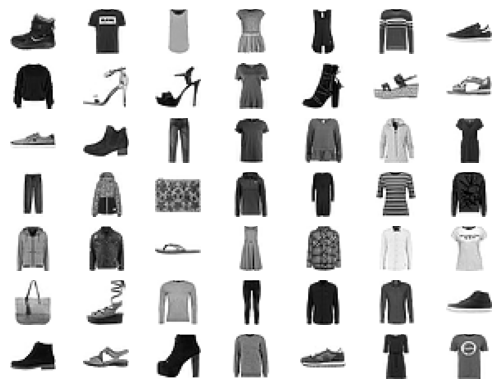

In [ ]:
# Load and plot the Fashion-MNIST dataset
from keras.datasets.fashion_mnist import load_data
from matplotlib import pyplot

# load the images into memory
(trainX, trainy), (testX, testy) = load_data()

# plot images from the training dataset
for i in range(49):
    # define subplot
    pyplot.subplot(7, 7, 1 + i)
    # turn off axis
    pyplot.axis('off')
    # plot raw pixel data
    pyplot.imshow(trainX[i], cmap='gray_r')

pyplot.show()

In [ ]:
print(trainX.shape)
print(trainy.shape)

(60000, 28, 28)
(60000,)


## Discriminator

In [ ]:
# define the discriminator model
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense
from keras.layers import Conv2D
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import LeakyReLU
from keras.layers import Input
from keras.utils import plot_model
import numpy as np

# define the standalone discriminator model (input: 28x28 grayscale image)
def define_discriminator(in_shape=(28,28,1)):
    model = Sequential()

    # downsample 28x28 -> 14x14
    model.add(Input(shape=in_shape))
    model.add(Conv2D(64, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.4))

    # downsample 14x14 -> 7x7
    model.add(Conv2D(64, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.4))

    # classifier
    model.add(Flatten())
    model.add(Dense(1, activation='sigmoid'))

    # compile model
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

In [ ]:
# define model
model = define_discriminator()

# summarize the model
model.summary()

# plot the model (needs pydot + graphviz; skipped if not installed)
try:
    plot_model(model, to_file='discriminator_plot.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('plot_model skipped:', e)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         3,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,705 (159.00 KB)

 Trainable params: 40,705 (159.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Function to load the dataset and scale it
# load and prepare Fashion-MNIST training images
def load_real_samples():
    # load fashion-mnist dataset
    (trainX, _), (_, _) = load_data()
    # expand to 3d, e.g. add channels dimension: (60000, 28, 28) -> (60000, 28, 28, 1)
    X = np.expand_dims(trainX, axis=-1)
    # convert from unsigned ints to floats
    X = X.astype('float32')
    # scale from [0, 255] to [-1, 1]
    X = (X - 127.5) / 127.5
    return X

In [ ]:
X = load_real_samples()
print(X.shape, X.min(), X.max())

(60000, 28, 28, 1) -1.0 1.0


In [ ]:
# select real samples (a half batch, e.g. 64 of 128); y is label 1 because they are real
def generate_real_samples(dataset, n_samples):
    # choose random instances
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    # retrieve selected images
    X = dataset[ix]
    # generate 'real' class labels (1)
    y = np.ones((n_samples, 1))
    return X, y

In [ ]:
# generate n random-noise "fake" samples with class labels (used only to test the discriminator before the generator exists)
def generate_fake_samples_noise(n_samples):
    # generate uniform random numbers in [0,1]
    X = np.random.rand(28 * 28 * 1 * n_samples)
    # update to have the range [-1, 1]
    X = -1 + X * 2
    # reshape into a batch of grayscale images
    X = X.reshape((n_samples, 28, 28, 1))
    # generate 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

In [ ]:
# train the discriminator model temporarily (against random noise images)
def train_discriminator(model, dataset, n_iter=100, n_batch=128):
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_iter):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator on real samples
        _, real_acc = model.train_on_batch(X_real, y_real)
        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples_noise(half_batch)
        # update discriminator on fake samples
        _, fake_acc = model.train_on_batch(X_fake, y_fake)
        # summarize performance
        print('>%d real=%.0f%% fake=%.0f%%' % (i+1, real_acc*100, fake_acc*100))

# Example Training
model = define_discriminator()
dataset = load_real_samples()
train_discriminator(model, dataset)

>1 real=16% fake=32%
>2 real=35% fake=38%
>3 real=44% fake=46%
>4 real=49% fake=50%
>5 real=54% fake=53%
>6 real=56% fake=56%
>7 real=59% fake=59%
>8 real=62% fake=62%
>9 real=64% fake=63%
>10 real=65% fake=65%
>11 real=67% fake=66%
>12 real=68% fake=68%
>13 real=69% fake=69%
>14 real=70% fake=70%
>15 real=71% fake=71%
>16 real=72% fake=72%
>17 real=73% fake=73%
>18 real=74% fake=74%
>19 real=75% fake=75%
>20 real=76% fake=76%
>21 real=77% fake=77%
>22 real=77% fake=78%
>23 real=78% fake=78%
>24 real=79% fake=79%
>25 real=80% fake=80%
>26 real=80% fake=81%
>27 real=81% fake=81%
>28 real=82% fake=82%
>29 real=82% fake=83%
>30 real=83% fake=83%
>31 real=84% fake=84%
>32 real=84% fake=84%
>33 real=85% fake=85%
>34 real=85% fake=85%
>35 real=85% fake=86%
>36 real=86% fake=86%
>37 real=86% fake=86%
>38 real=86% fake=87%
>39 real=87% fake=87%
>40 real=87% fake=87%
>41 real=87% fake=88%
>42 real=88% fake=88%
>43 real=88% fake=88%
>44 real=88% fake=88%
>45 real=88% fake=89%
>46 real=89% fake=8

## Generator

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Reshape, Conv2D, Conv2DTranspose, LeakyReLU, Input

# define the standalone generator model
def define_generator(latent_dim):
    model = Sequential()
    # foundation for 7x7 image
    n_nodes = 128 * 7 * 7
    model.add(Input(shape=(latent_dim,)))
    model.add(Dense(n_nodes))
    model.add(LeakyReLU(0.2))
    model.add(Reshape((7, 7, 128)))

    # upsample to 14x14
    model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
    model.add(LeakyReLU(0.2))

    # upsample to 28x28
    model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
    model.add(LeakyReLU(0.2))

    # output layer: 1 channel, tanh -> [-1, 1]
    model.add(Conv2D(1, (7,7), activation='tanh', padding='same'))
    return model

# define size of latent space & model summary
latent_dim = 100
model = define_generator(latent_dim)
model.summary()
try:
    plot_model(model, to_file='generator_plot.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print('plot_model skipped:', e)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,164,289 (4.44 MB)

 Trainable params: 1,164,289 (4.44 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
    # generate points in the latent space
    x_input = np.random.randn(latent_dim * n_samples)
    # reshape into a batch of inputs for the network
    x_input = x_input.reshape(n_samples, latent_dim)
    return x_input

# use the generator to generate n fake examples, with class labels
def generate_fake_samples(g_model, latent_dim, n_samples):
    # generate points in latent space
    x_input = generate_latent_points(latent_dim, n_samples)
    # predict outputs
    X = g_model.predict(x_input, verbose=0)
    # create 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

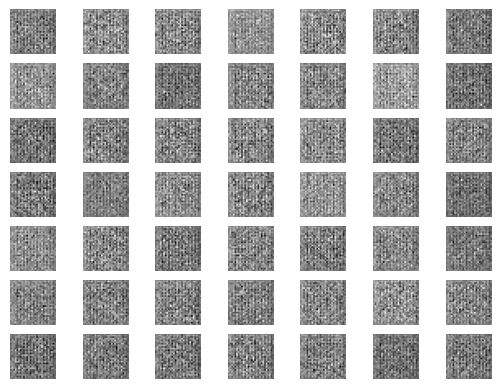

In [ ]:
# size of the latent space
latent_dim = 100

# define the generator model
model = define_generator(latent_dim)

# generate samples
n_samples = 49
X, _ = generate_fake_samples(model, latent_dim, n_samples)

# scale pixel values from [-1,1] to [0,1]
X = (X + 1) / 2.0

# plot the generated samples (untrained generator -> noise)
for i in range(n_samples):
    pyplot.subplot(7, 7, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(X[i, :, :, 0], cmap='gray_r')

pyplot.show()

## Combined GAN model

In [ ]:
# define the combined generator and discriminator model, for updating the generator
def define_gan(g_model, d_model):
    # make weights in the discriminator not trainable
    d_model.trainable = False
    # connect them
    model = Sequential()
    # add generator
    model.add(g_model)
    # add the discriminator
    model.add(d_model)
    # compile model
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    return model

## Training utilities

In [ ]:
# create and save a plot of generated images
def save_plot(examples, epoch, n=7):
    # scale from [-1,1] to [0,1]
    examples = (examples + 1) / 2.0
    # plot images
    for i in range(n * n):
        pyplot.subplot(n, n, 1 + i)
        pyplot.axis('off')
        pyplot.imshow(examples[i, :, :, 0], cmap='gray_r')
    # save plot to file
    filename = 'generated_plot_e%03d.png' % (epoch+1)
    pyplot.savefig(filename)
    pyplot.close()

# evaluate the discriminator, plot generated images, save generator model
def summarize_performance(epoch, g_model, d_model, dataset, latent_dim, n_samples=150):
    # prepare real samples
    X_real, y_real = generate_real_samples(dataset, n_samples)
    # evaluate discriminator on real examples
    _, acc_real = d_model.evaluate(X_real, y_real, verbose=0)
    # prepare fake examples
    x_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
    # evaluate discriminator on fake examples
    _, acc_fake = d_model.evaluate(x_fake, y_fake, verbose=0)
    # summarize discriminator performance
    print('>Epoch %d  Accuracy real: %.0f%%, fake: %.0f%%' % (epoch+1, acc_real*100, acc_fake*100))
    # keep for the evaluation plots
    history['acc_real'].append(acc_real)
    history['acc_fake'].append(acc_fake)
    history['acc_epoch'].append(epoch+1)
    # save plot
    save_plot(x_fake, epoch)
    # save the generator model file
    filename = 'generator_model_%03d.h5' % (epoch+1)
    g_model.save(filename)

In [ ]:
from numpy import ones

# store losses so the loss curves can be plotted after training
history = {'d_real': [], 'd_fake': [], 'g': [],            # per batch
           'd_epoch': [], 'g_epoch': [],                   # per epoch (mean)
           'acc_real': [], 'acc_fake': [], 'acc_epoch': []}

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=50, n_batch=128):
    bat_per_epo = int(dataset.shape[0] / n_batch)
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_epochs):
        d_ep, g_ep = [], []
        # enumerate batches over the training set
        for j in range(bat_per_epo):
            # discriminator must be trainable while it is being updated (safe on Keras 2 and Keras 3)
            d_model.trainable = True
            # get randomly selected 'real' samples
            X_real, y_real = generate_real_samples(dataset, half_batch)
            # update discriminator model weights
            d_loss1, _ = d_model.train_on_batch(X_real, y_real)
            # generate 'fake' examples
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
            # update discriminator model weights
            d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)
            # prepare points in latent space as input for the generator
            X_gan = generate_latent_points(latent_dim, n_batch)
            # create inverted labels for the fake samples
            y_gan = ones((n_batch, 1))
            # freeze the discriminator while the generator is updated
            d_model.trainable = False
            # update the generator via the discriminator's error
            g_loss = gan_model.train_on_batch(X_gan, y_gan)
            # record losses
            history['d_real'].append(d_loss1)
            history['d_fake'].append(d_loss2)
            history['g'].append(g_loss)
            d_ep.append((d_loss1 + d_loss2) / 2)
            g_ep.append(g_loss)
            # print progress every 100 batches (keeps the output readable)
            if (j+1) % 100 == 0:
                print('>%d, %d/%d, d1=%.3f, d2=%.3f g=%.3f' %
                      (i+1, j+1, bat_per_epo, d_loss1, d_loss2, g_loss))
        history['d_epoch'].append(np.mean(d_ep))
        history['g_epoch'].append(np.mean(g_ep))
        # evaluate the model performance, sometimes
        if (i+1) % 10 == 0:
            summarize_performance(i, g_model, d_model, dataset, latent_dim)

# size of the latent space
latent_dim = 100
# create the discriminator
d_model = define_discriminator()
# create the generator
g_model = define_generator(latent_dim)
# create the gan
gan_model = define_gan(g_model, d_model)
# load image data
dataset = load_real_samples()
# execute training (reduce n_epochs for a quicker run)
train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=5, n_batch=128)

>1, 100/468, d1=0.284, d2=0.283 g=2.033
>1, 200/468, d1=0.176, d2=0.176 g=2.820
>1, 300/468, d1=0.127, d2=0.127 g=3.436
>1, 400/468, d1=0.099, d2=0.099 g=3.904
>2, 100/468, d1=0.072, d2=0.072 g=4.524
>2, 200/468, d1=0.062, d2=0.062 g=4.824
>2, 300/468, d1=0.055, d2=0.055 g=5.096
>2, 400/468, d1=0.049, d2=0.049 g=5.351
>3, 100/468, d1=0.041, d2=0.041 g=5.677
>3, 200/468, d1=0.038, d2=0.038 g=5.878
>3, 300/468, d1=0.035, d2=0.035 g=6.055
>3, 400/468, d1=0.032, d2=0.032 g=6.215
>4, 100/468, d1=0.029, d2=0.029 g=6.452
>4, 200/468, d1=0.027, d2=0.027 g=6.589
>4, 300/468, d1=0.026, d2=0.026 g=6.707
>4, 400/468, d1=0.024, d2=0.024 g=6.834
>5, 100/468, d1=0.022, d2=0.022 g=7.035
>5, 200/468, d1=0.021, d2=0.021 g=7.121
>5, 300/468, d1=0.020, d2=0.020 g=7.224
>5, 400/468, d1=0.019, d2=0.019 g=7.326


## Evaluation
### 1. Generator and Discriminator loss curves

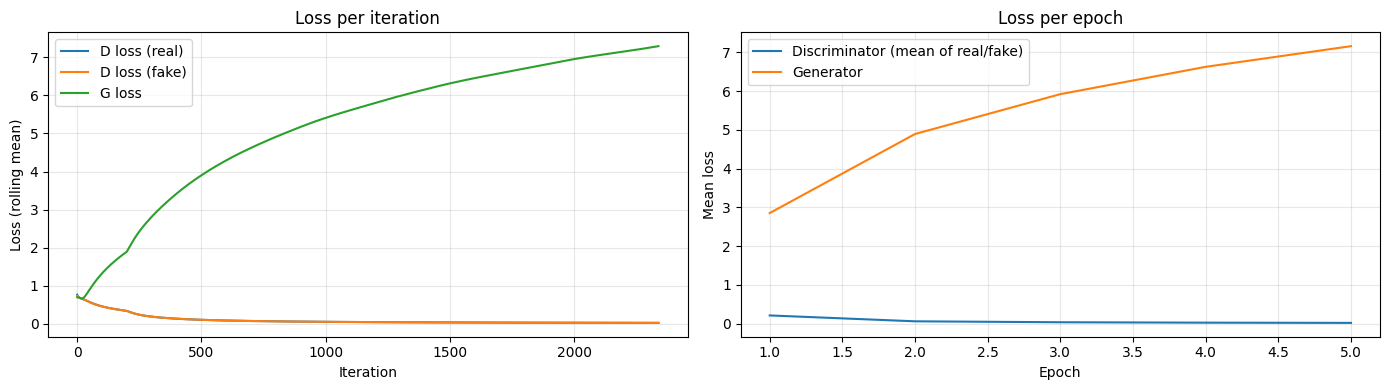

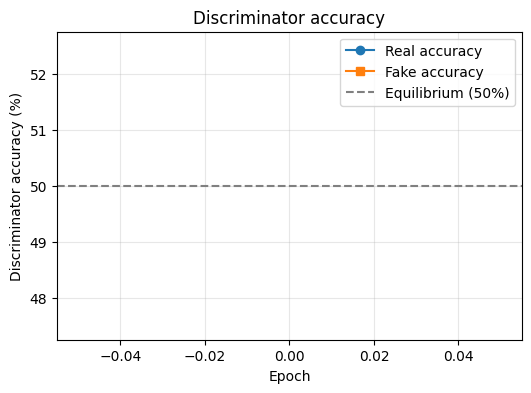

Final epoch  D loss: 0.021   G loss: 7.162


In [ ]:
import pandas as pd

# --- per-iteration losses (smoothed with a rolling mean) ---
def smooth(x, w=200):
    return pd.Series(x).rolling(w, min_periods=1).mean().values

pyplot.figure(figsize=(14, 4))

pyplot.subplot(1, 2, 1)
pyplot.plot(smooth(history['d_real']), label='D loss (real)')
pyplot.plot(smooth(history['d_fake']), label='D loss (fake)')
pyplot.plot(smooth(history['g']),      label='G loss')
pyplot.xlabel('Iteration'); pyplot.ylabel('Loss (rolling mean)')
pyplot.title('Loss per iteration'); pyplot.legend(); pyplot.grid(alpha=0.3)

# --- per-epoch mean losses ---
pyplot.subplot(1, 2, 2)
ep = range(1, len(history['g_epoch']) + 1)
pyplot.plot(ep, history['d_epoch'], label='Discriminator (mean of real/fake)')
pyplot.plot(ep, history['g_epoch'], label='Generator')
pyplot.xlabel('Epoch'); pyplot.ylabel('Mean loss')
pyplot.title('Loss per epoch'); pyplot.legend(); pyplot.grid(alpha=0.3)

pyplot.tight_layout()
pyplot.savefig('loss_curves.png', dpi=150)
pyplot.show()

# --- discriminator accuracy on real vs fake images ---
pyplot.figure(figsize=(6, 4))
pyplot.plot(history['acc_epoch'], np.array(history['acc_real'])*100, 'o-', label='Real accuracy')
pyplot.plot(history['acc_epoch'], np.array(history['acc_fake'])*100, 's-', label='Fake accuracy')
pyplot.axhline(50, color='gray', ls='--', label='Equilibrium (50%)')
pyplot.xlabel('Epoch'); pyplot.ylabel('Discriminator accuracy (%)')
pyplot.title('Discriminator accuracy'); pyplot.legend(); pyplot.grid(alpha=0.3)
pyplot.savefig('discriminator_accuracy.png', dpi=150)
pyplot.show()

print('Final epoch  D loss: %.3f   G loss: %.3f' % (history['d_epoch'][-1], history['g_epoch'][-1]))

### 2. Generate synthetic images with the trained generator

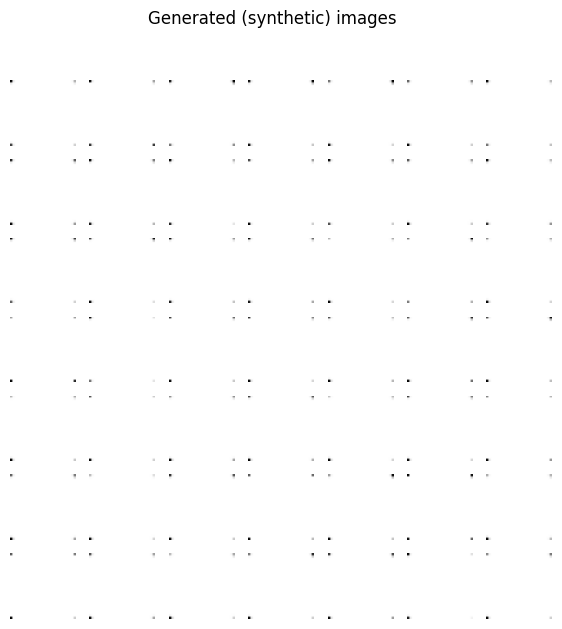

In [ ]:
# generate a fresh batch of synthetic images from random latent vectors
n = 7
X_gen, _ = generate_fake_samples(g_model, latent_dim, n * n)
X_gen = (X_gen + 1) / 2.0

pyplot.figure(figsize=(7, 7))
for i in range(n * n):
    pyplot.subplot(n, n, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(X_gen[i, :, :, 0], cmap='gray_r')
pyplot.suptitle('Generated (synthetic) images')
pyplot.savefig('final_generated_images.png', dpi=150)
pyplot.show()

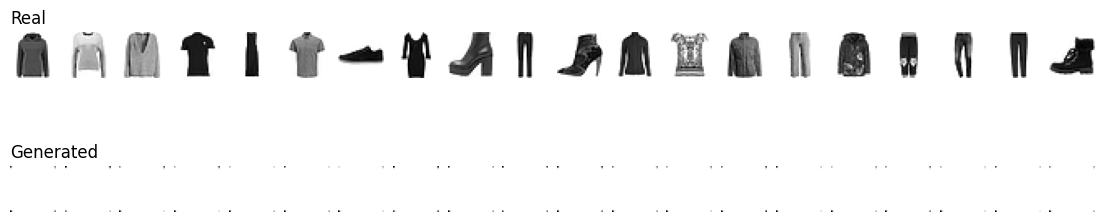

In [ ]:
# side-by-side comparison: real vs generated
X_real_show, _ = generate_real_samples(dataset, 20)
X_fake_show, _ = generate_fake_samples(g_model, latent_dim, 20)
X_real_show = (X_real_show + 1) / 2.0
X_fake_show = (X_fake_show + 1) / 2.0

pyplot.figure(figsize=(14, 3.2))
for i in range(20):
    pyplot.subplot(2, 20, 1 + i);  pyplot.axis('off'); pyplot.imshow(X_real_show[i, :, :, 0], cmap='gray_r')
    if i == 0: pyplot.title('Real', loc='left')
    pyplot.subplot(2, 20, 21 + i); pyplot.axis('off'); pyplot.imshow(X_fake_show[i, :, :, 0], cmap='gray_r')
    if i == 0: pyplot.title('Generated', loc='left')
pyplot.show()

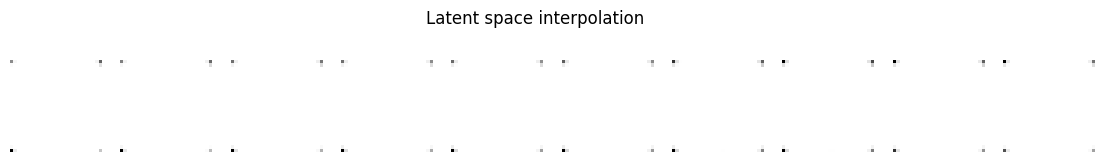

In [ ]:
# latent space interpolation: smooth transitions show the generator learned a continuous manifold
def interpolate_points(p1, p2, n_steps=10):
    ratios = np.linspace(0, 1, num=n_steps)
    return np.asarray([(1.0 - r) * p1 + r * p2 for r in ratios])

pts = generate_latent_points(latent_dim, 2)
interp = interpolate_points(pts[0], pts[1], 10)
X_int = (g_model.predict(interp, verbose=0) + 1) / 2.0

pyplot.figure(figsize=(14, 2))
for i in range(10):
    pyplot.subplot(1, 10, 1 + i)
    pyplot.axis('off')
    pyplot.imshow(X_int[i, :, :, 0], cmap='gray_r')
pyplot.suptitle('Latent space interpolation')
pyplot.show()

### 3. Analysis

**Loss curves**
- In a healthy GAN the discriminator loss stays roughly around 0.5-0.7 (it can't separate real from fake much better than chance), while the generator loss rises above its starting value early on and then fluctuates in a band (typically ~0.7-1.5) instead of collapsing to 0 or diverging.
- A discriminator loss going to ~0 with a rapidly growing generator loss would mean the discriminator is winning (training failure / vanishing gradients). A generator loss near 0 with a high discriminator loss would suggest the generator is fooling a weak discriminator, or mode collapse.
- GAN losses are **not monotonic** - they oscillate because the two networks compete, so a flat/stable adversarial balance is the sign of good training, not a steadily falling loss.

**Discriminator accuracy**
- Accuracy on real and fake images that stays near 50% (roughly 40-70%) means the two networks are balanced and the generated images are hard to distinguish from the real ones.

**Image quality**
- Early epochs produce noise/blobs; by later epochs the generator should produce recognisable Fashion-MNIST items (shirts, trousers, shoes, bags, etc.) with clear outlines and variety.
- Check for **mode collapse** (many identical-looking images) - the 7x7 grid and interpolation plot show diversity and smooth transitions in the latent space.
- Saved snapshots `generated_plot_eXXX.png` (every 10 epochs) let you compare quality as training progresses; more epochs generally sharpen the details.